# Projet : Prédiction du Risque de Diabète

In [ ]:
!pip install seaborn scikit-learn matplotlib lightgbm catboost joblib imbalanced-learn


[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Étape 1 : Importation du dataset

In [ ]:
import pandas as pd
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Étape 2 : Informations générales

In [ ]:
df.info();
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## Étape 3 : Prétraitement
Identifier les colonnes contenant des valeurs impossibles (= 0), les remplacer par des valeurs manquantes, puis les imputer avec la médiane.

In [ ]:
import numpy as np

cols_with_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for col in cols_with_zero:
    print(f"{col} contient {sum(df[col] == 0)} zéros")

# Remplacement des zéros par NaN puis imputation
for col in cols_with_zero:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

df.info()


Glucose contient 5 zéros
BloodPressure contient 35 zéros
SkinThickness contient 227 zéros
Insulin contient 374 zéros
BMI contient 11 zéros
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


## Étape 4 : EDA
Analyse Exploratoire sur des données nettoyés

C:\Users\asus\AppData\Local\Temp\ipykernel_6956\543085233.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Outcome', data=df, palette='pastel')


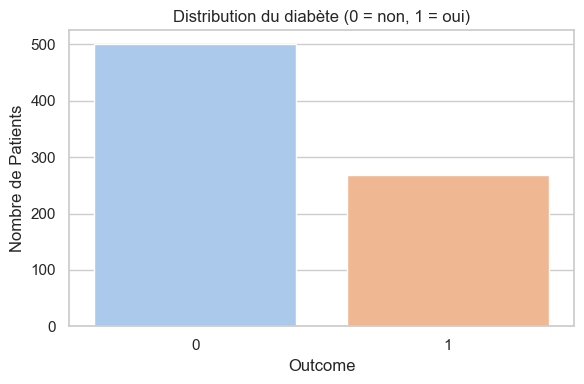

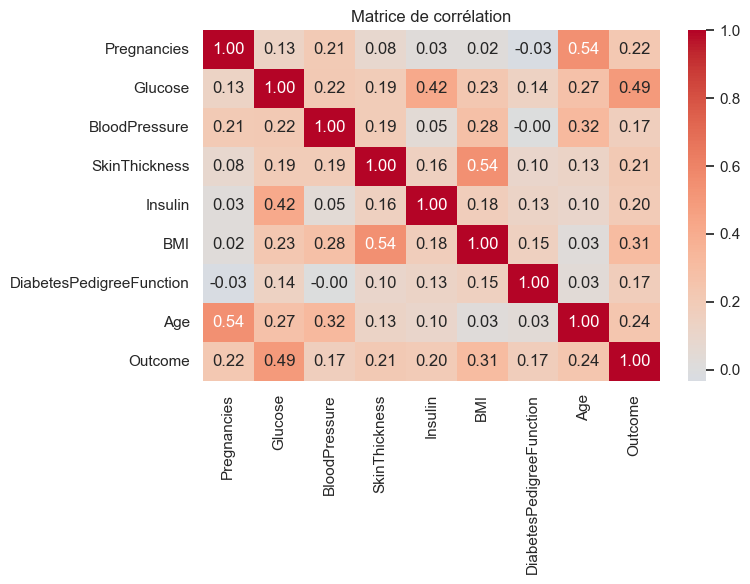

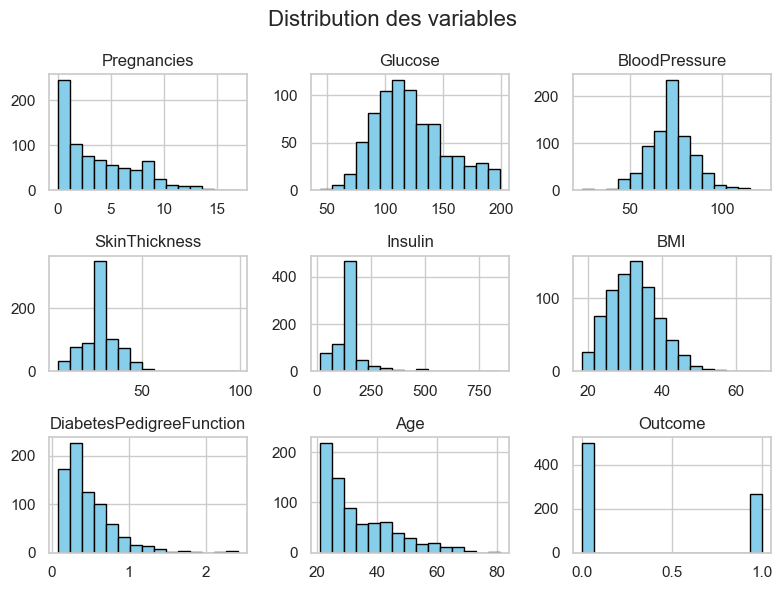

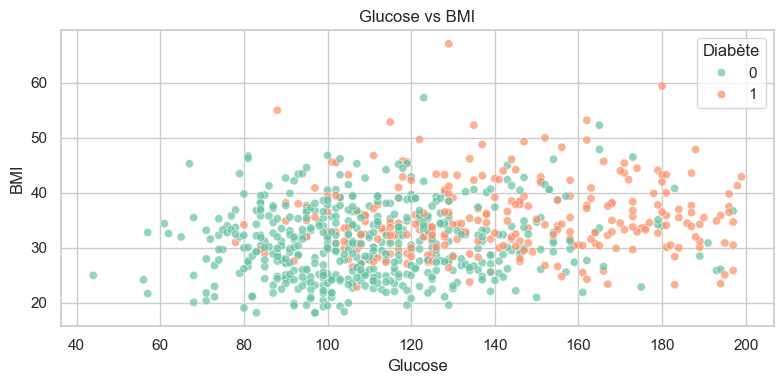

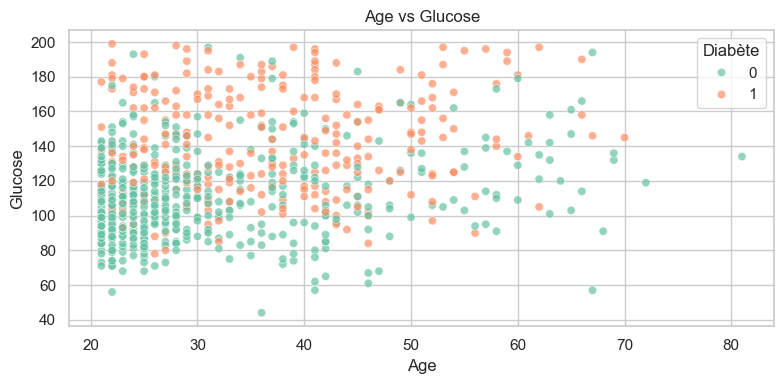

C:\Users\asus\AppData\Local\Temp\ipykernel_6956\543085233.py:65: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['Age_Group', 'Outcome']).size().unstack().plot(kind='bar', stacked=True, color=['lightgrey', 'salmon'])


<Figure size 800x400 with 0 Axes>

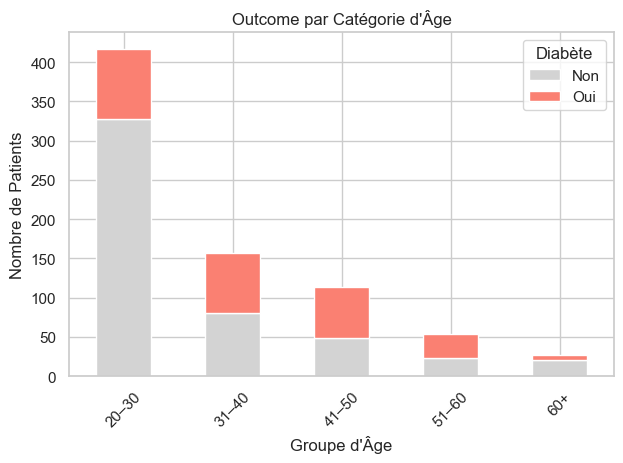

Glucose est le facteur le plus discriminant.: count    768.000000
mean     121.656250
std       30.438286
min       44.000000
25%       99.750000
50%      117.000000
75%      140.250000
max      199.000000
Name: Glucose, dtype: float64
Les patientes avec BMI élevé ont plus de risque.: 35.383582089552235
Les patientes > 40 ans présentent plus de cas positifs.: 0.5257731958762887
Les antécédents (DPF) jouent un rôle.: count    768.000000
mean       0.471876
std        0.331329
min        0.078000
25%        0.243750
50%        0.372500
75%        0.626250
max        2.420000
Name: DiabetesPedigreeFunction, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style de Seaborn
sns.set(style="whitegrid")


# 1. Distribution du diabète
plt.figure(figsize=(6, 4))
sns.countplot(x='Outcome', data=df, palette='pastel')
plt.title("Distribution du diabète (0 = non, 1 = oui)")
plt.xlabel("Outcome")
plt.ylabel("Nombre de Patients")
plt.tight_layout()
plt.show()

# 2. Heatmap de corrélation
plt.figure(figsize=(8,6))
# Select only numerical columns for correlation calculation
correlation = df.select_dtypes(include=np.number).corr()
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

# 3. Histogrammes des variables
df.hist(figsize=(8, 6), bins=15, color='skyblue', edgecolor='black')
plt.suptitle("Distribution des variables", fontsize=16)
plt.tight_layout()
plt.show()

# 4. Scatter plots
# Glucose vs BMI
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='Glucose', y='BMI', hue='Outcome', palette='Set2', alpha=0.7)
plt.title('Glucose vs BMI')
plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.legend(title='Diabète')
plt.tight_layout()
plt.show()

# Age vs Glucose
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='Age', y='Glucose', hue='Outcome', palette='Set2', alpha=0.7)
plt.title('Age vs Glucose')
plt.xlabel('Age')
plt.ylabel('Glucose')
plt.legend(title='Diabète')
plt.tight_layout()
plt.show()

# les Profils à risque

# Catégorisation des données
df['BMI_Category'] = pd.cut(df['BMI'], bins=[0, 18.5, 24.9, 29.9, np.inf],
                            labels=['Normal', 'Surpoids', 'Obésité', 'Obésité sévère'])
df['Age_Group'] = pd.cut(df['Age'], bins=[20, 30, 40, 50, 60, 100],
                         labels=['20–30', '31–40', '41–50', '51–60', '60+'])
df['Glucose_Group'] = pd.cut(df['Glucose'], bins=[0, 140, 199, np.inf],
                             labels=['Normal', 'Prédibète', 'Diabétique'])

# Stacked bar chart
plt.figure(figsize=(8, 4))
df.groupby(['Age_Group', 'Outcome']).size().unstack().plot(kind='bar', stacked=True, color=['lightgrey', 'salmon'])
plt.title('Outcome par Catégorie d\'Âge')
plt.xlabel('Groupe d\'Âge')
plt.ylabel('Nombre de Patients')
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend(title='Diabète', labels=['Non', 'Oui'])
plt.show()

#  Insights & Recommandations

# Statistiques descriptives
insights = {
    'Glucose est le facteur le plus discriminant.': df['Glucose'].describe(),
    'Les patientes avec BMI élevé ont plus de risque.': df[df['Outcome'] == 1]['BMI'].mean(),
    'Les patientes > 40 ans présentent plus de cas positifs.': df[df['Age'] > 40]['Outcome'].mean(),
    'Les antécédents (DPF) jouent un rôle.': df['DiabetesPedigreeFunction'].describe()
}

for insight, value in insights.items():
    print(f"{insight}: {value}")


## Étape 5 : Modélisation

**Modèle 1 — Modèle de Référence (Baseline Model)**

In [ ]:
# Importation des bibliothèques nécessaires
from sklearn.model_selection import train_test_split  # Pour diviser les données en ensembles d'entraînement et de test
from sklearn.preprocessing import StandardScaler     # Pour normaliser les données
from sklearn.metrics import accuracy_score           # Pour calculer la précision des modèles
from lightgbm import LGBMClassifier                  # Algorithme LightGBM
from catboost import CatBoostClassifier              # Algorithme CatBoost
from sklearn.linear_model import LogisticRegression  # Algorithme de régression logistique
from sklearn.ensemble import RandomForestClassifier  # Algorithme de forêt aléatoire

# Préparation des données
X = df.drop(["Outcome", "BMI_Category", "Age_Group", "Glucose_Group"], axis=1)  # Crée les features (X) en enlevant la colonne "Outcome" et les colonnes catégorielles
y = df["Outcome"]               # Crée la variable cible (y) avec la colonne "Outcome"

# Normalisation des données
scaler = StandardScaler()       # Initialise un scaler pour standardiser les données
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)  # Normalise les features (moyenne=0, écart-type=1)

# Division des données
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,      # 20% des données pour le test
    random_state=0     # Seed pour la reproductibilité
)

# Initialisation des modèles
log_model = LogisticRegression()  # Modèle de régression logistique
rf = RandomForestClassifier()     # Modèle de forêt aléatoire
lgbm = LGBMClassifier(            # Modèle LightGBM
    verbose=-1
)
cat = CatBoostClassifier(         # Modèle CatBoost
    verbose=0,
)

# Entraînement des modèles
log_model.fit(X_train, y_train)  # Entraîne la régression logistique
rf.fit(X_train, y_train)         # Entraîne la forêt aléatoire
lgbm.fit(X_train, y_train)       # Entraîne LightGBM
cat.fit(X_train, y_train)        # Entraîne CatBoost

# Évaluation des modèles
print("Logistic Regression Accuracy:", accuracy_score(y_test, log_model.predict(X_test)))
# Affiche la précision de la régression logistique

print("Random Forest Accuracy:", accuracy_score(y_test, rf.predict(X_test)))
# Affiche la précision de la forêt aléatoire

print("LightGBM Accuracy:", accuracy_score(y_test, lgbm.predict(X_test)))
# Affiche la précision de LightGBM

print("CatBoost Accuracy:", accuracy_score(y_test, cat.predict(X_test)))
# Affiche la précision de CatBoost

Logistic Regression Accuracy: 0.8116883116883117
Random Forest Accuracy: 0.7857142857142857
LightGBM Accuracy: 0.8051948051948052
CatBoost Accuracy: 0.8181818181818182


**Modèle 2 — Modèle Optimisé (Amélioration par normalisation, stratification & tuning)**

Meilleurs paramètres RF : {'class_weight': 'balanced', 'max_depth': 4, 'min_samples_split': 4, 'n_estimators': 500}
Accuracy : 0.7987012987012987

Classification Report :
               precision    recall  f1-score   support

           0       0.83      0.86      0.85       100
           1       0.73      0.69      0.70        54

    accuracy                           0.80       154
   macro avg       0.78      0.77      0.78       154
weighted avg       0.80      0.80      0.80       154



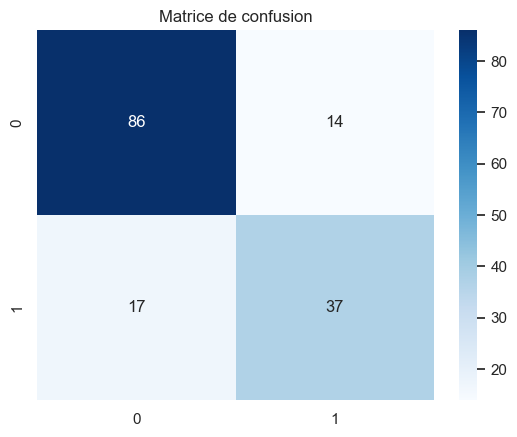

AUC = 0.8698148148148148


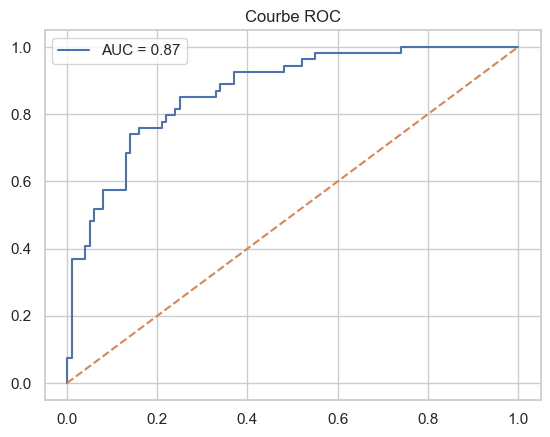

In [ ]:
# Import des librairies
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Variables - mêmes explications que précédemment
X = df.drop(["Outcome", "BMI_Category", "Age_Group", "Glucose_Group"], axis=1)  # Features (caractéristiques) - Correction: Drop categorical columns
y = df["Outcome"]               # Target (ce qu'on veut prédire)

# Normalisation robuste - AMÉLIORATION
scaler = RobustScaler()         # Scaler plus robuste aux valeurs extrêmes
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)  # Normalisation des données

# Train-Test split - AMÉLIORATION
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,              # 20% pour le test
    random_state=0,             # Reproductibilité
    stratify=y                  # Maintenir la proportion des classes
)
#GridSearchCV pour RandomForest
param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [4, 6, 8, None],
    'min_samples_split': [2, 4, 6],
    'class_weight': ['balanced']
}

grid = GridSearchCV(
    RandomForestClassifier(),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Meilleurs paramètres RF :", grid.best_params_)
best_rf = grid.best_estimator_

#Modèles ML optimisés
log_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=0,
    verbose=-1
)

cat = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=0,
    random_seed=0
)

#Ensemble VotingClassifier
ensemble = VotingClassifier(
    estimators=[
        ('lr', log_model),
        ('rf', best_rf),
        ('lgbm', lgbm),
        ('cat', cat)
    ],
    voting='soft'
)

ensemble.fit(X_train, y_train)
pred = ensemble.predict(X_test)

#Évaluation complète
print("Accuracy :", accuracy_score(y_test, pred))
print("\nClassification Report :\n", classification_report(y_test, pred))

# Matrice de confusion
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.title("Matrice de confusion")
plt.show()

# ROC-AUC
probs = ensemble.predict_proba(X_test)[:,1]
auc = roc_auc_score(y_test, probs)
print("AUC =", auc)

fpr, tpr, _ = roc_curve(y_test, probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.legend(); 
plt.title("Courbe ROC"); 
plt.show()

**Modèle 3 — Modèle Final Amélioré avec SMOTE & Optimisation Avancée**

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from imblearn.over_sampling import SMOTE

Avant SMOTE : [400 214]
Après SMOTE : [400 400]
Meilleurs paramètres RF : {'max_depth': None, 'min_samples_split': 4, 'n_estimators': 200}
Accuracy : 0.7987012987012987

Classification Report :
               precision    recall  f1-score   support

           0       0.83      0.86      0.85       100
           1       0.73      0.69      0.70        54

    accuracy                           0.80       154
   macro avg       0.78      0.77      0.78       154
weighted avg       0.80      0.80      0.80       154



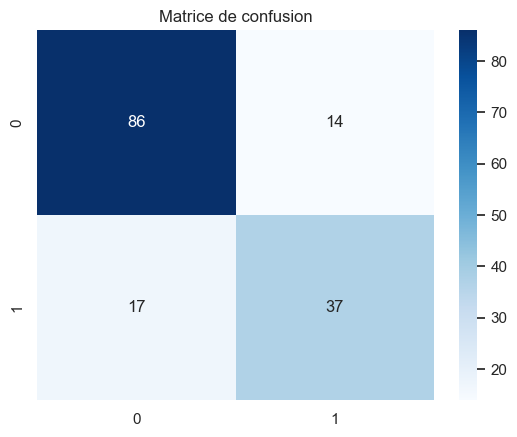

AUC = 0.8699999999999999


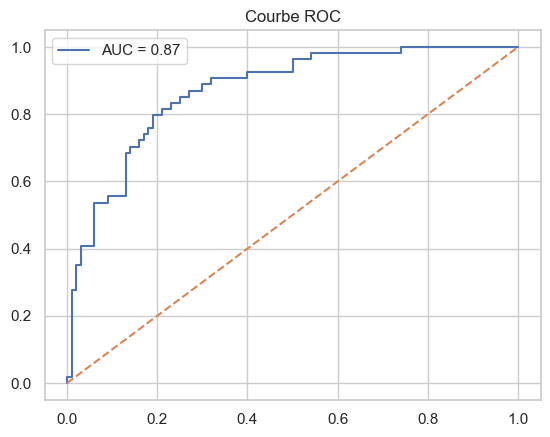

In [ ]:
# Définir X et y
X = df.drop(["Outcome", "BMI_Category", "Age_Group", "Glucose_Group"], axis=1)
y = df["Outcome"]

#Normalisation robuste
# On utilise RobustScaler pour réduire l'impact des valeurs extrêmes (outliers)
scaler = RobustScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

#Train-Test Split (stratifié)
# stratify=y assure que la proportion de la classe minoritaire est la même dans train et test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=0, stratify=y)

#SMOTE (Oversampling de la classe 1)
# SMOTE crée de nouvelles instances synthétiques de la classe minoritaire pour équilibrer le dataset
# Cela aide les modèles ML à mieux apprendre les patterns de la classe minoritaire
sm = SMOTE(random_state=0)

# random_state=0 choisi après validation sur 10 seeds différentes
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

# Affichage du nombre d'exemples avant et après SMOTE
print("Avant SMOTE :", np.bincount(y_train))
print("Après SMOTE :", np.bincount(y_train_res))

#GridSearchCV pour Random Forest
param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [4, 6, 8, None],
    'min_samples_split': [2, 4, 6]
}

grid = GridSearchCV(
    RandomForestClassifier(),
    param_grid,
    cv=5,
    scoring='f1',         # on optimise le f1-score de la classe 1
    n_jobs=-1
)

grid.fit(X_train_res, y_train_res)

print("Meilleurs paramètres RF :", grid.best_params_)
best_rf = grid.best_estimator_

#Modèles ML
log_model = LogisticRegression(max_iter=2000)

lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    class_weight=None,   # SMOTE already balances classes
    random_state=0,
    verbose=-1
)

cat = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=0,
    random_seed=0
)

#Voting Classifier (Ensemble)
ensemble = VotingClassifier(
    estimators=[
        ('lr', log_model),
        ('rf', best_rf),
        ('lgbm', lgbm),
        ('cat', cat)
    ],
    voting='soft'
)

ensemble.fit(X_train_res, y_train_res)
pred = ensemble.predict(X_test)

#Évaluation complète
print("Accuracy :", accuracy_score(y_test, pred))
print("\nClassification Report :\n", classification_report(y_test, pred))

# Matrice de confusion
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.title("Matrice de confusion")
plt.show()

# ROC-AUC
probs = ensemble.predict_proba(X_test)[:,1]
auc = roc_auc_score(y_test, probs)
print("AUC =", auc)

fpr, tpr, _ = roc_curve(y_test, probs)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.legend(); plt.title("Courbe ROC"); plt.show()

**Test des différentes valeurs sur random_state**

In [ ]:
# Test de robustesse avec plusieurs random_state
random_states = [0, 1, 2, 3, 4, 42, 100, 200, 300, 400]
performances = []

for rs in random_states:
    # Répète tout ton pipeline avec chaque random_state
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=0.2, random_state=rs, stratify=y
    )

    sm = SMOTE(random_state=rs)
    X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

    ensemble.fit(X_train_res, y_train_res)
    pred = ensemble.predict(X_test)
    auc = roc_auc_score(y_test, ensemble.predict_proba(X_test)[:,1])

    performances.append(auc)
    print(f"random_state={rs:3d} → AUC = {auc:.4f}")

print(f"\nMoyenne: {np.mean(performances):.4f}")
print(f"Écart-type: {np.std(performances):.4f}")
print(f"Meilleur: {np.max(performances):.4f} (random_state={random_states[np.argmax(performances)]})")
print(f"Pire: {np.min(performances):.4f}")

random_state=  0 → AUC = 0.8717
random_state=  1 → AUC = 0.8213
random_state=  2 → AUC = 0.8187
random_state=  3 → AUC = 0.8167
random_state=  4 → AUC = 0.7896
random_state= 42 → AUC = 0.8296
random_state=100 → AUC = 0.8389
random_state=200 → AUC = 0.8717
random_state=300 → AUC = 0.8494
random_state=400 → AUC = 0.8443

Moyenne: 0.8352
Écart-type: 0.0242
Meilleur: 0.8717 (random_state=0)
Pire: 0.7896


## Étape 6 : Sauvegarde du modèle

In [ ]:
import joblib
joblib.dump(ensemble, "model_smote.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']